# Task 56: Feature Importance Technical Report

Rank features using standardized coefficients, validation permutation impact, and exact Shapley attribution; compare global/local views and explain selection trade-offs.

Validation baseline F1: 0.881 held-out test metrics: {'accuracy': np.float64(0.8032786885245902), 'precision': np.float64(0.7692307692307693), 'recall': np.float64(0.9090909090909091), 'f1': np.float64(0.8333333333333333)}


,Feature,Coefficient |weight|,Permutation F1 drop mean,Permutation SD,Mean |SHAP|,SHAP SD across cases,Consensus mean rank
2,cp,0.6448,0.0714,0.0164,0.1111,0.0770,1.6667
11,ca,0.6308,0.0527,0.0478,0.1163,0.0637,2.0000
8,exang,0.5400,0.0114,0.0137,0.1263,0.0650,2.6667
1,sex,0.5145,0.0192,0.0165,0.0959,0.0852,3.6667
12,thal,0.4955,0.0057,0.0158,0.0775,0.0891,5.3333
9,oldpeak,0.4096,0.0072,0.0145,0.0239,0.0284,6.6667
3,trestbps,0.3643,-0.0176,0.0145,0.0450,0.0486,8.6667
10,slope,0.3362,-0.0130,0.0125,0.0447,0.0378,8.6667
7,thalach,0.2508,-0.0052,0.0092,0.0221,0.0253,9.0000
4,chol,0.1595,-0.0061,0.0083,0.0240,0.0268,9.3333


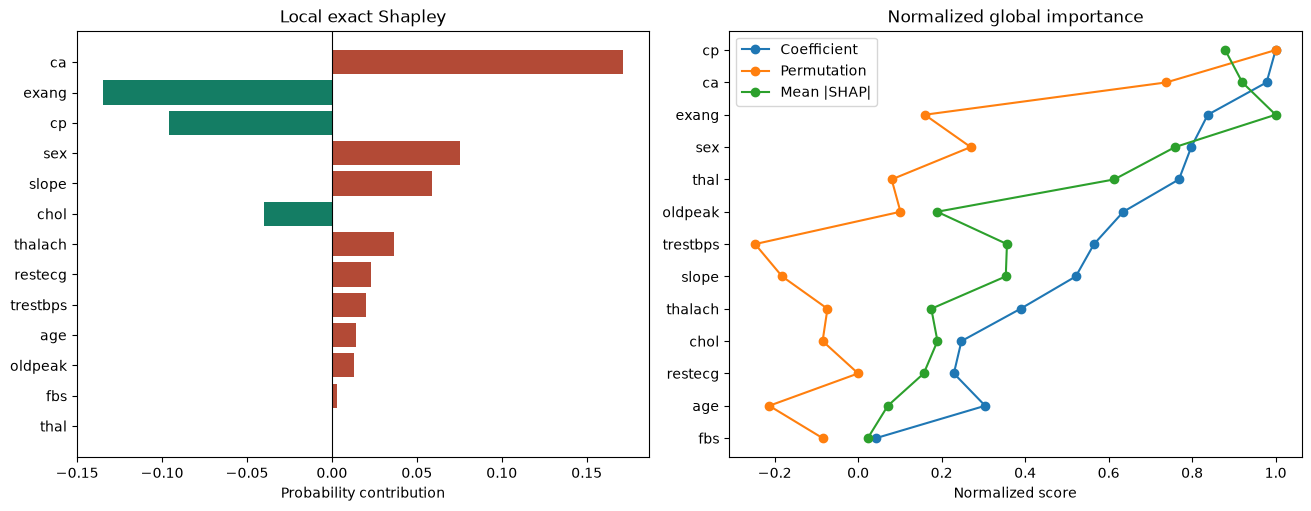

Selection rationale: prefer features that rank highly across independent methods, inspect permutation uncertainty, and verify case-level directions. Coefficients are model-conditional; permutation is affected by correlated substitutes; SHAP depends on its background. None proves causality or feature suitability for care.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_56_Feature_Importance_Technical_Report/heart.csv'),Path('Heart_Disease_Tasks/Task_56_Feature_Importance_Technical_Report/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)
def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)

def manual_metrics(actual,pred):
    tp=np.sum((actual==1)&(pred==1));tn=np.sum((actual==0)&(pred==0));fp=np.sum((actual==0)&(pred==1));fn=np.sum((actual==1)&(pred==0))
    precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.
    return {'accuracy':(tp+tn)/len(actual),'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.}
trainval,test=split(y,.8,56);train,val=split(y[trainval],.8,57);train,val=trainval[train],trainval[val]
Xtr,Xv,Xte=X[train],X[val],X[test];ytr,yv,yte=y[train],y[val],y[test]
mean,scale=Xtr.mean(0),Xtr.std(0);scale[scale==0]=1;Xtr,Xv,Xte=(Xtr-mean)/scale,(Xv-mean)/scale,(Xte-mean)/scale
class Logistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1400):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y;self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def proba(self,x):return 1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))
    def predict(self,x):return (self.proba(x)>=.5).astype(int)
model=Logistic().fit(Xtr,ytr);base_f1=manual_metrics(yv,model.predict(Xv))['f1']

# Validation permutation importance: independently shuffle one feature and record F1 drop.
rng=np.random.default_rng(560);drops=np.zeros((5,len(features)))
for repeat in range(5):
    for j in range(len(features)):
        altered=Xv.copy();altered[:,j]=rng.permutation(altered[:,j])
        drops[repeat,j]=base_f1-manual_metrics(yv,model.predict(altered))['f1']

# Exact interventional Shapley values for a modest held-out case sample.
background=Xtr[np.linspace(0,len(Xtr)-1,min(8,len(Xtr)),dtype=int)]
def exact_shap(instance):
    p=len(instance);masks=np.arange(1<<p,dtype=np.int64);bits=1<<np.arange(p);included=(masks[:,None]&bits[None,:])!=0;coalition=np.zeros(len(masks))
    for start in range(0,len(masks),128):
        stop=min(start+128,len(masks));hybrids=np.where(included[start:stop,None,:],instance[None,None,:],background[None,:,:])
        coalition[start:stop]=model.proba(hybrids.reshape(-1,p)).reshape(stop-start,len(background)).mean(1)
    phi=np.zeros(p);denom=math.factorial(p)
    for j in range(p):
        bit=1<<j
        for mask in masks[(masks&bit)==0]:
            size=int(mask).bit_count();phi[j]+=math.factorial(size)*math.factorial(p-size-1)/denom*(coalition[mask|bit]-coalition[mask])
    return float(coalition[0]),phi
case_ids=np.linspace(0,len(Xte)-1,min(6,len(Xte)),dtype=int);shap_matrix=[]
for index in case_ids:shap_matrix.append(exact_shap(Xte[index])[1])
shap_matrix=np.asarray(shap_matrix)

# Normalize each method's positive importance scale before forming a consensus rank.
coefficient=np.abs(model.w);permutation=drops.mean(0);shap=np.mean(np.abs(shap_matrix),axis=0)
def ranks(values):
    order=np.argsort(values,kind='stable');result=np.empty(len(values),float)
    for rank,index in enumerate(order):result[index]=rank+1
    return result
methods={'standardized |coefficient|':coefficient,'validation F1 drop':permutation,'mean |SHAP|':shap}
rank_matrix=np.vstack([ranks(-values) for values in methods.values()])
importance=pd.DataFrame({'Feature':features,'Coefficient |weight|':coefficient,'Permutation F1 drop mean':permutation,'Permutation SD':drops.std(0,ddof=1),'Mean |SHAP|':shap,'SHAP SD across cases':shap_matrix.std(0),'Consensus mean rank':rank_matrix.mean(0)}).sort_values('Consensus mean rank')
print('Validation baseline F1:',round(base_f1,3),'held-out test metrics:',manual_metrics(yte,model.predict(Xte)))
display(importance.round(4))

# Explain a single test prediction locally.
local_index=0;local_base,local_phi=exact_shap(Xte[local_index]);assert np.isclose(local_base+local_phi.sum(),model.proba(Xte[local_index:local_index+1])[0],atol=1e-8)
local=pd.Series(local_phi,index=features).sort_values(key=np.abs,ascending=True)
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
axes[0].barh(local.index,local.values,color=np.where(local.values>=0,'#b34a36','#147d64'));axes[0].axvline(0,color='black',linewidth=.8);axes[0].set_title('Local exact Shapley');axes[0].set_xlabel('Probability contribution')
ordered=importance.sort_values('Consensus mean rank',ascending=False)
for column,label in [('Coefficient |weight|','Coefficient'),('Permutation F1 drop mean','Permutation'),('Mean |SHAP|','Mean |SHAP|')]:
    values=ordered[column].to_numpy();scale_value=np.max(np.abs(values));axes[1].plot(values/scale_value if scale_value else values,ordered['Feature'],marker='o',label=label)
axes[1].set_title('Normalized global importance');axes[1].legend();axes[1].set_xlabel('Normalized score');plt.show()
print('Selection rationale: prefer features that rank highly across independent methods, inspect permutation uncertainty, and verify case-level directions. Coefficients are model-conditional; permutation is affected by correlated substitutes; SHAP depends on its background. None proves causality or feature suitability for care.')